## London household income: baseline checkpoint

In [1]:
import numpy as np
from pathlib import Path
import pandas as pd
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

In [2]:
# Locate the CSV file
data_path = Path("lsoa-data.csv")
if not data_path.exists():
    data_path = Path("final/lsoa-data.csv")

# Load the data and remove empty rows
df = pd.read_csv(data_path, encoding="cp1252", low_memory=False)
print("Original shape:", df.shape)

df = df.dropna(how="all").reset_index(drop=True)
print("Cleaned shape:", df.shape)

Original shape: (4837, 277)
Cleaned shape: (4835, 277)


In [3]:
# Select and rename the eight input features
feature_columns = {
    "Qualifications;% No qualifications;2011": "no_qualifications",
    "Qualifications;% Highest level of qualification: Level 4 qualifications and above;2011": "higher_qualifications",
    "Economic Activity;Employment Rate;2011": "employment_rate",
    "Economic Activity;Unemployment Rate;2011": "unemployment_rate",
    "Tenure;Social rented (%);2011": "social_rented",
    "Tenure;Private rented (%);2011": "private_rented",
    "Household Composition;% Lone parent household;2011": "lone_parent",
    "Household Composition;% One person household;2011": "one_person"
}

target_column = (
    "Household Income, 2011/12;Median Annual Household Income estimate (£)"
)

# Build the input matrix, target, and borough labels
X_all = df[list(feature_columns)].rename(columns=feature_columns).astype(float)
y_all = df[target_column].astype(float).rename("median_income")
groups_all = df["Names"].str.replace(r" \d{3}[A-Z]$", "", regex=True)

print("Input shape:", X_all.shape)
print("Target shape:", y_all.shape)
print("Borough groups:", groups_all.nunique())

# Check only the fields used for modeling
missing = X_all.isna().sum().sum() + y_all.isna().sum()
print("Missing values in selected inputs and target:", missing)


Input shape: (4835, 8)
Target shape: (4835,)
Borough groups: 33
Missing values in selected inputs and target: 0


## Reserving the Final Testing Set

Reserve whole boroughs for final testing. All cross-validation and plots below use the development set only. These holdout boroughs were included in an earlier exploratory baseline, but are excluded from subsequent fitting, tuning, and checkpoint scoring.

In [4]:
# Fix the final test split by sampling whole boroughs with seed 42
holdout_seed = 42
holdout_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=holdout_seed)
dev_idx, final_test_idx = next(holdout_split.split(X_all, groups=groups_all))

# Use only the development data for all modeling below
X_dev = X_all.iloc[dev_idx].reset_index(drop=True)
y_dev = y_all.iloc[dev_idx].reset_index(drop=True)
groups_dev = groups_all.iloc[dev_idx].reset_index(drop=True)
holdout_boroughs = sorted(groups_all.iloc[final_test_idx].unique())

assert set(groups_dev).isdisjoint(holdout_boroughs)

print(f"Development: {len(dev_idx):,} LSOAs in {groups_dev.nunique()} borough groups")
print(f"Final holdout: {len(final_test_idx):,} LSOAs "
      f"({len(final_test_idx) / len(X_all):.1%}) in {len(holdout_boroughs)} borough groups")
print("Holdout boroughs:", ", ".join(holdout_boroughs))

display(pd.concat([X_dev, y_dev], axis=1).head())


Development: 3,767 LSOAs in 26 borough groups
Final holdout: 1,068 LSOAs (22.1%) in 7 borough groups
Holdout boroughs: Ealing, Enfield, Havering, Hounslow, Kensington and Chelsea, Richmond upon Thames, Wandsworth


,no_qualifications,higher_qualifications,employment_rate,unemployment_rate,social_rented,private_rented,lone_parent,one_person,median_income
0,20.0,44.2,58.6,9.9,54.4,13.7,21.1,33.0,30223.0
1,15.0,50.4,62.3,8.0,52.6,14.0,13.2,50.8,32049.0
2,9.6,61.9,65.7,4.9,18.6,18.8,7.3,30.1,58469.0
3,18.0,47.2,58.8,8.8,51.3,15.0,15.7,38.6,31551.0
4,4.9,65.2,71.8,2.1,1.9,19.4,3.7,29.1,73024.0


## Baselines and validation

The constant baseline predicts each training fold's mean. OLS uses eight predictors and an intercept. For each model, compare one borough-grouped five-fold run with five shuffled five-fold runs.

In [5]:
# Define the two validation schemes on the same development rows
grouped_folds = list(GroupKFold(n_splits=5).split(X_dev, groups=groups_dev))
shuffled_seeds = (42, 43, 44, 45, 46)
shuffled_folds = {
    seed: list(KFold(n_splits=5, shuffle=True, random_state=seed).split(X_dev))
    for seed in shuffled_seeds
}

# Use fixed baselines: neither model has hyperparameters to tune
baseline_models = {
    "Training mean": DummyRegressor(strategy="mean"),
    "OLS": make_pipeline(StandardScaler(), LinearRegression(fit_intercept=True)),
}


def predict_out_of_fold(predictors, folds):
    # The pipeline fits the OLS scaler only on each training fold
    return pd.DataFrame({
        name: cross_val_predict(model, predictors, y_dev, cv=folds)
        for name, model in baseline_models.items()
    }, index=y_dev.index)


# Reuse each set of folds for both models
baseline_predictions = predict_out_of_fold(X_dev, grouped_folds)
shuffled_predictions = {
    seed: predict_out_of_fold(X_dev, folds)
    for seed, folds in shuffled_folds.items()
}


## MAE and uncertainty

MAE is pooled across development LSOAs. Shuffled MAE averages absolute errors across the five seeds. The 95% percentile intervals resample whole development boroughs 1,000 times, keeping models and validation schemes paired.

In [6]:
# Measure absolute errors before averaging across shuffled runs
grouped_errors = baseline_predictions.sub(y_dev, axis=0).abs()
shuffled_errors = {
    seed: predictions.sub(y_dev, axis=0).abs()
    for seed, predictions in shuffled_predictions.items()
}
shuffled_seed_mae = pd.DataFrame({
    seed: errors.mean() for seed, errors in shuffled_errors.items()
}).T.rename_axis("Seed")

# Use the same borough resamples for all models and validation schemes
borough_sizes = groups_dev.value_counts().sort_index()
rng = np.random.default_rng(42)
draws = rng.integers(0, len(borough_sizes), size=(1000, len(borough_sizes)))
sampled_sizes = borough_sizes.to_numpy()[draws].sum(axis=1)


def summarize_mae(grouped, shuffled):
    # Average each LSOA's absolute error across shuffled seeds
    shuffled_average = sum(shuffled.values()) / len(shuffled)
    summaries = {}

    for model in grouped.columns:
        errors = pd.DataFrame({
            "Shuffled": shuffled_average[model],
            "Borough-grouped": grouped[model],
        })
        errors["Grouped minus shuffled"] = errors["Borough-grouped"] - errors["Shuffled"]

        # Resample whole boroughs and weight by their LSOA counts
        totals = errors.groupby(groups_dev).sum().reindex(borough_sizes.index).to_numpy()
        bootstrap_mae = totals[draws].sum(axis=1) / sampled_sizes[:, None]
        lower, upper = np.percentile(bootstrap_mae, [2.5, 97.5], axis=0)
        summaries[model] = pd.DataFrame({
            "MAE (£)": errors.mean(),
            "95% lower (£)": lower,
            "95% upper (£)": upper,
        })

    return pd.concat(summaries, names=["Model", "Validation"])


baseline_results = summarize_mae(grouped_errors, shuffled_errors)

# Show one row per model and keep the numeric results for plotting
formatted_mae = {}
for (model, scheme), row in baseline_results.iterrows():
    formatted_mae[model, scheme] = (
        f"{row['MAE (£)']:,.2f} "
        f"[{row['95% lower (£)']:,.2f}, {row['95% upper (£)']:,.2f}]"
    )

report_table = pd.Series(formatted_mae).unstack().rename(columns={
    "Shuffled": "Shuffled MAE (£)",
    "Borough-grouped": "Grouped MAE (£)",
    "Grouped minus shuffled": "MAE change (£)",
}).reindex(index=list(baseline_models), columns=[
    "Shuffled MAE (£)", "Grouped MAE (£)", "MAE change (£)"
]).rename_axis("Model")

print("Values are estimates [95% borough bootstrap interval].")
display(report_table)

# Summarize seed variability without displaying the full seed table
seed_ranges = [
    f"{model}: £{scores.min():,.2f}–£{scores.max():,.2f}"
    for model, scores in shuffled_seed_mae.items()
]
print("Shuffled MAE range across five seeds: " + "; ".join(seed_ranges))


Values are estimates [95% borough bootstrap interval].


,Shuffled MAE (£),Grouped MAE (£),MAE change (£)
Model,,,
Training mean,"8,680.39 [8,040.76, 9,416.69]","8,686.69 [8,048.52, 9,415.30]","6.30 [-26.13, 33.00]"
OLS,"3,511.32 [3,100.19, 3,975.00]","3,633.09 [3,189.47, 4,124.51]","121.77 [46.52, 194.05]"


Shuffled MAE range across five seeds: Training mean: £8,678.94–£8,683.46; OLS: £3,506.44–£3,515.00


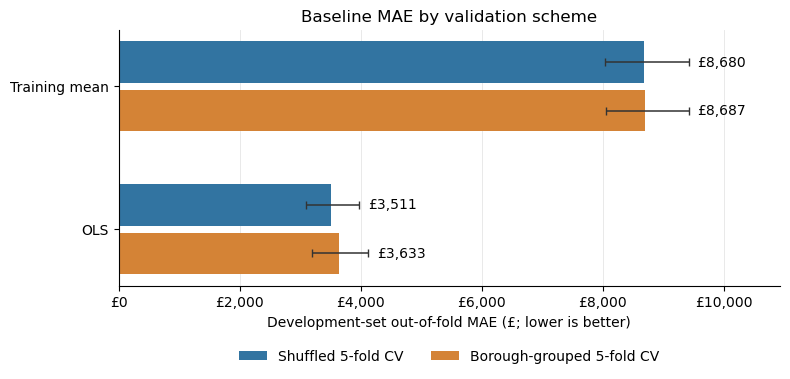

In [7]:
# Compare both validation schemes side by side for each baseline
schemes = [
    ("Shuffled", "Shuffled 5-fold CV", "#3274A1"),
    ("Borough-grouped", "Borough-grouped 5-fold CV", "#D48336"),
]
model_names = list(baseline_models)
positions = np.arange(len(model_names))
bar_height = 0.29

fig, ax = plt.subplots(figsize=(8, 4))
for offset, (scheme, label, color) in zip((-0.17, 0.17), schemes):
    results = baseline_results.xs(scheme, level="Validation").reindex(model_names)
    mae = results["MAE (£)"].to_numpy()
    lower = results["95% lower (£)"].to_numpy()
    upper = results["95% upper (£)"].to_numpy()

    # Error bars show the 95% borough bootstrap interval for each MAE
    ax.barh(
        positions + offset, mae, height=bar_height, color=color, label=label,
        xerr=np.vstack([mae - lower, upper - mae]),
        error_kw={"ecolor": "#333333", "capsize": 3, "linewidth": 1.1},
        zorder=2,
    )
    for y_position, estimate, upper_bound in zip(positions + offset, mae, upper):
        ax.text(upper_bound + 145, y_position, f"£{estimate:,.0f}",
                va="center", fontsize=10)

ax.set_yticks(positions, labels=model_names)
ax.invert_yaxis()
ax.set(
    title="Baseline MAE by validation scheme",
    xlabel="Development-set out-of-fold MAE (£; lower is better)",
    xlim=(0, baseline_results["95% upper (£)"].max() * 1.16),
)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"£{value:,.0f}"))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#E5E5E5", linewidth=0.6)
ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=2, frameon=False)

fig.tight_layout()
fig.savefig(data_path.parent / "baseline_mae_by_validation.png", dpi=300, bbox_inches="tight")
plt.show()


## OLS prediction diagnostic

Compare predictions with published income estimates using the borough-grouped development folds.

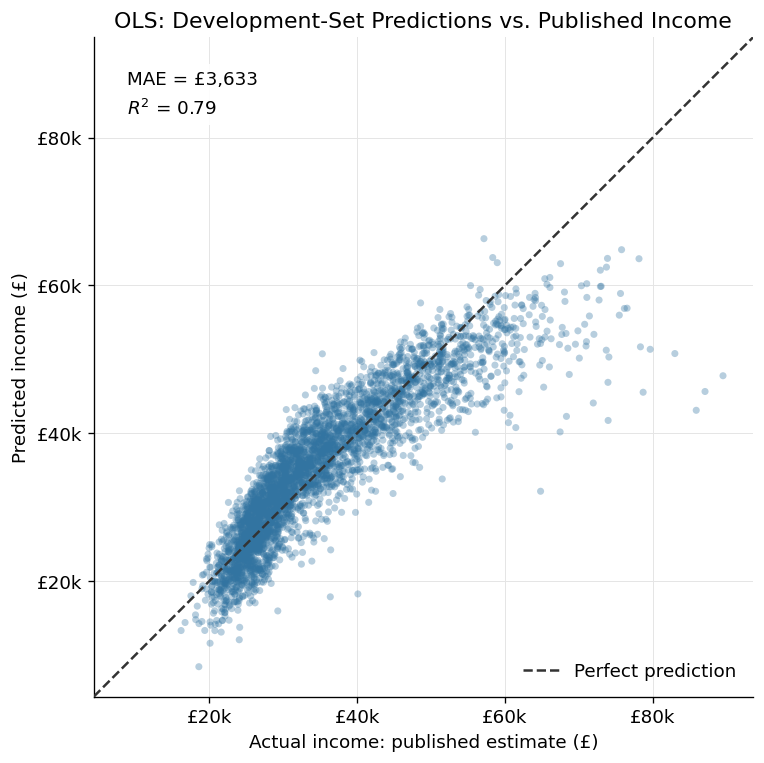

In [8]:
actual = y_dev.to_numpy()
predicted = baseline_predictions["OLS"].to_numpy()

mae = mean_absolute_error(actual, predicted)
r2 = r2_score(actual, predicted)

with plt.rc_context({"font.size": 11, "font.family": "DejaVu Sans"}):
    fig, ax = plt.subplots(figsize=(6.5, 6.5))

    # Keep both axes on the same scale
    values = np.concatenate([actual, predicted])
    padding = (values.max() - values.min()) * 0.05
    limits = (values.min() - padding, values.max() + padding)

    # Plot development-set out-of-fold predictions
    ax.scatter(
        actual, predicted,
        s=18,
        alpha=0.35,
        color="#3274A1",
        edgecolors="none",
        rasterized=True,
        zorder=2
    )

    # Draw the perfect prediction line
    ax.plot(
        limits, limits,
        color="#333333",
        linestyle="--",
        linewidth=1.5,
        label="Perfect prediction",
        zorder=3
    )

    ax.set(
        xlim=limits,
        ylim=limits,
        xlabel="Actual income: published estimate (£)",
        ylabel="Predicted income (£)",
        title="OLS: Development-Set Predictions vs. Published Income"
    )
    ax.set_aspect("equal", adjustable="box")

    # Use matching ticks and display income in thousands
    ticks = MaxNLocator(nbins=5).tick_values(*limits)
    ticks = ticks[(ticks >= limits[0]) & (ticks <= limits[1])]
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)

    formatter = FuncFormatter(lambda value, _: f"£{value / 1000:,.0f}k")
    ax.xaxis.set_major_formatter(formatter)
    ax.yaxis.set_major_formatter(formatter)

    # Add evaluation metrics
    ax.text(
        0.05, 0.95,
        f"MAE = £{mae:,.0f}\n$R^2$ = {r2:.2f}",
        transform=ax.transAxes,
        va="top",
        linespacing=1.6,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.9)
    )

    # Simplify the figure styling
    ax.grid(color="#E5E5E5", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower right", frameon=False)

    fig.tight_layout()

    # Export publication-quality versions
    fig.savefig("ols_actual_vs_predicted_development_cv.pdf", bbox_inches="tight")
    fig.savefig("ols_actual_vs_predicted_development_cv.png", dpi=300, bbox_inches="tight")

    plt.show()